# Show Me Where It Says That — hands-on

*Agents that cite every word in a document · Data Science Dojo*

DPT-3 Verity, the newest parsing model in LandingAI's Agentic Document Extraction (ADE), returns **every
word** of a digitally created document with its page, its box on the page and a confidence score.
This notebook follows the slides: each heading names the slide it goes with. The hands-on stops end
with a **Your turn** cell.

| Slide | Part | What you build |
|---|---|---|
| 5 | What Verity returns | read one grounded word |
| 7 | A · Cite | find an exact phrase and box it on the page |
| 8–9 | B · Route | send low-confidence words to a person |
| 10 | C · Verify | tie every extracted value to the words it came from |
| 11–15 | D · Version control | find every edit between lease revisions, on the page |

Everything runs on saved responses in `data/`. **No API key is needed.**

## Slide 3 · Setup check

Run this cell. You should see four parsed leases of about 550 words each and one saved extraction.
Then drop a thumbs-up in chat.

In [1]:
import sys, json
sys.path.insert(0, "scripts")
from IPython.display import Image, display
import docdiff, patterns, text_diff_baseline, evaluate

for name in ["lease_v1", "lease_v1_reflow", "lease_v2", "lease_v3"]:
    print(f"{name:<16} {len(patterns.words(name))} words")
print("saved extraction:", list(json.loads(open("data/extracted/lease_v3.json").read())["extraction"]))

lease_v1         551 words
lease_v1_reflow  551 words
lease_v2         553 words
lease_v3         562 words
saved extraction: ['landlord', 'late_fee', 'monthly_rent', 'premises_address', 'security_deposit', 'tenants', 'term_end', 'term_start']


## Slide 5 · What Verity returns

A parse response holds the markdown and a `structure` tree of pages, text blocks, tables and cells.
Every block carries `atomic_grounding`: one entry per word with its character range, page, box
(0–1 of the page width and height) and confidence. `patterns.words()` flattens that into a list.

In [2]:
parse = json.loads(open("data/parsed/lease_v3.json").read())
meta = parse["metadata"]
print(meta["model_version"], "|", meta["page_count"], "pages |", meta["billing"]["total_credits"], "credits")

words = patterns.words("lease_v3")
w = next(w for w in words if w.text == "$95.00")
print(w)

dpt-3-verity-20260804-preview | 2 pages | 0.7 credits
Word(text='$95.00', page=1, box={'xmax': 0.43509, 'xmin': 0.38392, 'ymax': 0.68005, 'ymin': 0.66721}, confidence=1.0, block='table_cell-4', start=1667, end=1673)


## Slide 7 · A. Cite — finding a phrase is finding it on the page

Match the words, then draw their boxes. No image search, no re-OCR.

page 1, x 0.38-0.44, y 0.67-0.68, lowest confidence 1.00


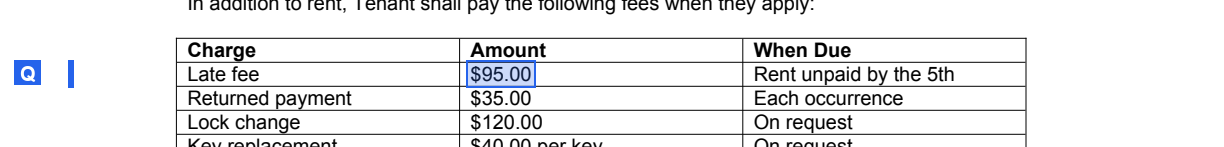

In [3]:
hit = patterns.cite("lease_v3", "$95.00")[0]
print(patterns.describe(hit))
display(patterns.show_cite("lease_v3", hit))

### Your turn (slide 7)

1. Cite **“thirty-one (31) days”** in `lease_v3`.
2. Cite a phrase that wraps onto a second line, for example **“Portland, Oregon 97205”**. How many boxes does the highlight draw?

'thirty-one (31) days': 1 hit(s)
   page 1, x 0.42-0.56, y 0.56-0.58, lowest confidence 1.00
   lines: [0.56]


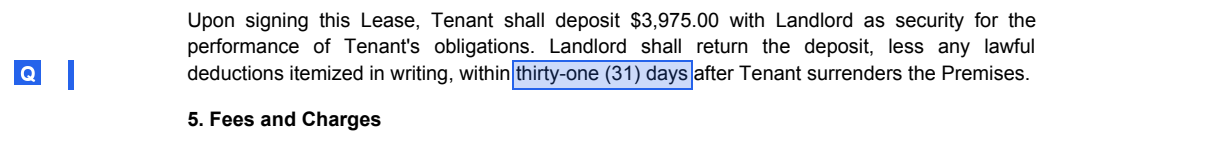

'Portland, Oregon 97205': 1 hit(s)
   page 1, 2 lines: x 0.78-0.85, y 0.24-0.25 | x 0.15-0.26, y 0.26-0.27, lowest confidence 1.00
   lines: [0.24, 0.26]


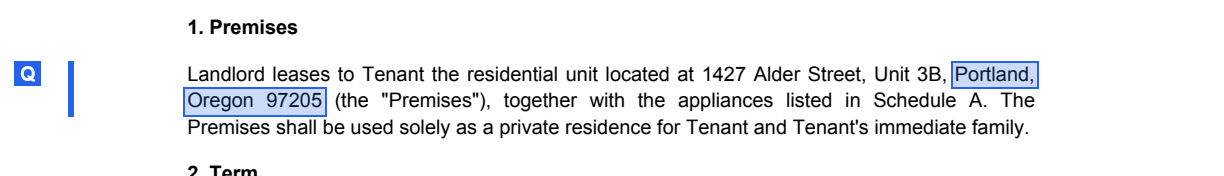

In [4]:
# Solution
for phrase in ["thirty-one (31) days", "Portland, Oregon 97205"]:
    hits = patterns.cite("lease_v3", phrase)
    print(f"{phrase!r}: {len(hits)} hit(s)")
    for h in hits:
        print("  ", patterns.describe(h))
        print("   lines:", sorted({round(w.box['ymin'], 2) for w in h}))
        display(patterns.show_cite("lease_v3", h))
# "Portland," ends one line and "Oregon 97205" starts the next, so the highlight draws two boxes.

## Slide 8 · B. Route — a person checks only what needs checking

Any block holding a word below 0.95 confidence goes to review; everything else flows straight through.
0.95 is the threshold the ADE Playground uses to highlight words.

lease_v1         551 words  2 below 0.95  ->  2 of 31 blocks to review   '("Tenant").' 0.79, '$75.00' 0.87
lease_v2         553 words  2 below 0.95  ->  1 of 30 blocks to review   'Alteratioos' 0.68, 'clean' 0.93
lease_v3         562 words  0 below 0.95  ->  0 of 34 blocks to review   
lease_v1_reflow  551 words  1 below 0.95  ->  1 of 30 blocks to review   'alterations' 0.86


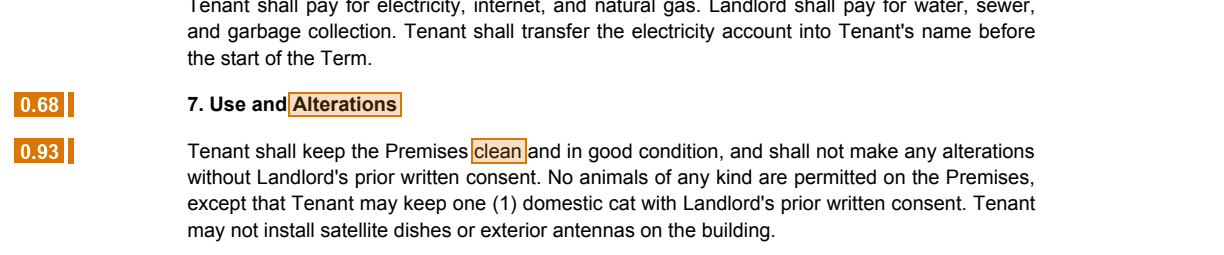

In [5]:
for name in ["lease_v1", "lease_v2", "lease_v3", "lease_v1_reflow"]:
    r = patterns.route(name)
    print(f"{name:<16} {r['words']} words  {len(r['low_words'])} below 0.95  ->  "
          f"{len(r['review_blocks'])} of {r['blocks']} blocks to review   "
          + ", ".join(f"{w.text!r} {w.confidence:.2f}" for w in r["low_words"]))
display(patterns.show_route("lease_v2"))

### Your turn (slide 8)

Lower the threshold to **0.90**. Which words leave the review queue?

In [6]:
# Solution
threshold = 0.90
for name in ["lease_v1", "lease_v2", "lease_v3", "lease_v1_reflow"]:
    r = patterns.route(name, threshold)
    print(f"{name:<16}", [(w.text, round(w.confidence, 2)) for w in r["low_words"]])
# Only "clean" (0.93) leaves the queue. The real misread, Alteratioos (0.68), stays in it.

lease_v1         [('("Tenant").', 0.79), ('$75.00', 0.87)]
lease_v2         [('Alteratioos', 0.68)]
lease_v3         []
lease_v1_reflow  [('alterations', 0.86)]


**Before you read on:** five words out of 2,214 were flagged. Look at the amber boxes above.
How many of the five do you think are actually *wrong*?

## Slide 9 · Check this, not this is wrong

Only **one**. `Alteratioos` (0.68) is a real misread: the page says *Alterations*. `clean` (0.93),
`$75.00` (0.87), `("Tenant").` (0.79) and `alterations` (0.86) were all read correctly.

**A low score means “check this”, not “this is wrong.”** A pipeline that throws low-confidence words away
loses four correct reads to catch one bad one. Remember `$75.00`: it's the late fee, and it comes back on slide 14.

## Slide 10 · C. Verify — every extracted value, tied to its words

ADE Extract returns values plus *evidence*: the character spans it read them from. Those spans cover whole
blocks (a paragraph, a table). Verity's words narrow each one to the exact words, with their own
confidence. A value that can't be found among its cited words goes to a person.

`data/extracted/lease_v3.json` is a saved extraction; the schema is `data/schema/lease_terms.json`.

1  landlord          Cedar Row Properties LLC                   verified             page 1, x 0.22-0.44, y 0.15-0.16, lowest confidence 1.00
2  late_fee          95.0                                       verified             page 1, x 0.38-0.44, y 0.67-0.68, lowest confidence 1.00
3  monthly_rent      2650.0                                     verified             page 1, x 0.41-0.49, y 0.44-0.45, lowest confidence 1.00
4  premises_address  1427 Alder Street, Unit 3B, Portland, Or   verified             page 1, 2 lines: x 0.57-0.85, y 0.24-0.25 | x 0.15-0.26, y 0.26-0.27, lowest confidence 0.98
5  security_deposit  3975.0                                     verified             page 1, x 0.51-0.59, y 0.53-0.54, lowest confidence 1.00
6  tenants           Daniel R. Okafor and Mei Lin Okafor        verified             page 1, x 0.15-0.44, y 0.16-0.17, lowest confidence 1.00
7  term_end          August 31, 2027                            verified             page 1, x 0.62-0.75, y 0.33

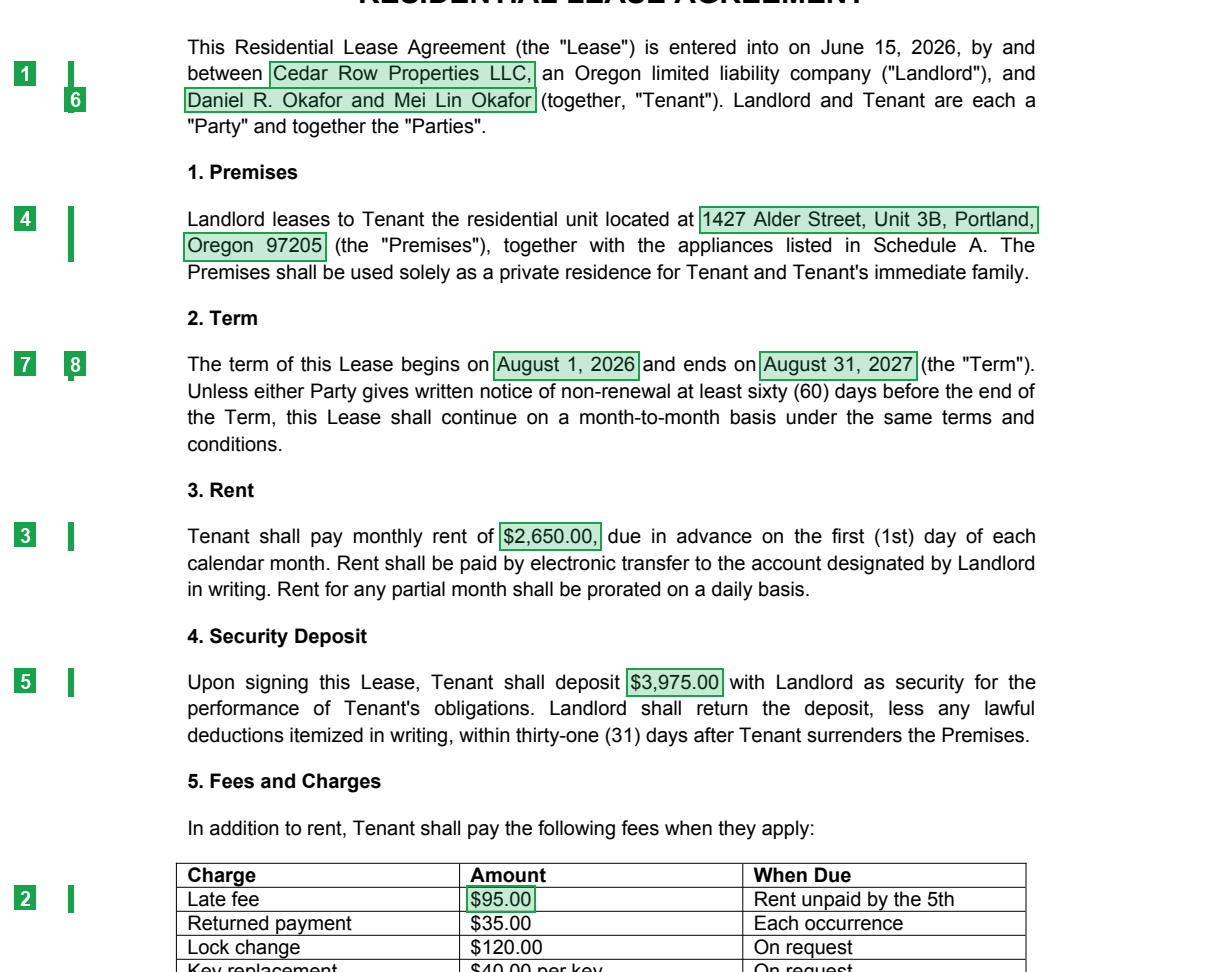

In [7]:
saved = json.loads(open("data/extracted/lease_v3.json").read())
rows = patterns.verify("lease_v3", saved["extraction"], saved["evidence"])
for i, r in enumerate(rows, 1):
    print(f"{i}  {r['field']:<17} {str(r['value'])[:40]:<42} {r['status']:<20} {r['where']}")
display(patterns.show_verify("lease_v3", rows))

In [8]:
stale = dict(saved["extraction"], late_fee=75.0)   # v1's old late fee
for r in patterns.verify("lease_v3", stale, saved["evidence"]):
    if r["status"] != "verified":
        print(r["field"], r["value"], "->", r["status"])

late_fee 75.0 -> not in cited words


### Your turn (slide 10)

Change **`tenants`** to a name that isn't in the lease. What does `verify` say?

In [9]:
# Solution
wrong = dict(saved["extraction"], tenants="Daniel R. Okafor and Priya Okafor")
for r in patterns.verify("lease_v3", wrong, saved["evidence"]):
    print(f"{r['field']:<17} {r['status']}")
# tenants -> "not in cited words". One wrong word in an otherwise right answer is enough.

landlord          verified
late_fee          verified
monthly_rent      verified
premises_address  verified
security_deposit  verified
tenants           not in cited words
term_end          verified
term_start        verified


# Slide 11 · D. Use case: document version control

| File | What it is |
|---|---|
| `lease_v1.pdf` | the original draft |
| `lease_v1_reflow.pdf` | **the same words** as v1, new font and margins |
| `lease_v2.pdf` | the landlord's counter-offer, 6 edits |
| `lease_v3.pdf` | the final version, 5 more edits |

Every planned edit is in `data/ground_truth.json`, so we can score what we build.

## Slide 12 · Why a text diff fails on PDFs

In [10]:
for old, new in text_diff_baseline.PAIRS:
    total, d = text_diff_baseline.line_diff(old, new)
    print(f"{old} -> {new}: {len(d)} changed lines")

lease_v1 -> lease_v1_reflow: 64 changed lines
lease_v1 -> lease_v2: 70 changed lines


lease_v2 -> lease_v3: 14 changed lines


`lease_v1` and its re-flowed copy have **no edits at all**, yet every line that wrapped differently counts as changed.

## Slide 12 · Compare words, not lines

Flatten each parse into one reading-order stream of words (text and table cells, no headers or footers),
then align the two streams with `difflib.SequenceMatcher`. Whatever doesn't line up is a change.

In [11]:
print("v1 vs its re-flowed copy:", len(docdiff.diff("lease_v1", "lease_v1_reflow")), "changes")

def show(changes):
    for c in changes:
        flag = "   " if c.status == "change" else "~  "
        print(f"{flag}{c.id:<4}{c.kind:<9}{c.section[:22]:<24}{c.old_text[:30]!r:<34}-> {c.new_text[:38]!r}  conf {c.min_confidence:.2f}")

show(docdiff.diff("lease_v1", "lease_v2", rule="off"))

v1 vs its re-flowed copy: 0 changes
   C1  removed  1. Premises             'Landlord shall provide one (1)'  -> ''  conf 1.00
   C2  modified 2. Term                 'July'                            -> 'August'  conf 1.00
   C3  modified 2. Term                 'thirty (30)'                     -> 'sixty (60)'  conf 1.00
   C4  modified 3. Rent                 '$2,450.00,'                      -> '$2,650.00,'  conf 1.00
   C5  modified 5. Fees and Charges     '$75.00'                          -> '$95.00'  conf 0.87
   C6  modified 7. Use and Alteratioos  'Alterations'                     -> 'Alteratioos'  conf 0.68
   C7  added    7. Use and Alteratioos  ''                                -> 'except that Tenant may keep one (1) do'  conf 1.00


All six edits are there, including the late fee inside the table. But `Alterations` → `Alteratioos`
is not an edit: it's Verity's misread from slide 9.

## Slide 13 · Five steps

That's the whole pipeline in `scripts/docdiff.py`, about 270 lines:

1. **Parse** with Verity: every word with page, box and confidence.
2. **Flatten** text and table cells into one reading-order stream, leaving out headers and footers.
3. **Align** the two streams with `difflib`; whatever doesn't line up is a change.
4. **Classify** each change: a real edit, or a misread to set aside?
5. **Render** each change on the original pages.

Step 4 is where confidence earns its keep, and where it's easy to get wrong.

## Slide 14 · The confidence trap

The obvious fix is to hide every change that touches a low-confidence word:

In [12]:
show(docdiff.diff("lease_v1", "lease_v2", rule="naive"))

   C1  removed  1. Premises             'Landlord shall provide one (1)'  -> ''  conf 1.00
   C2  modified 2. Term                 'July'                            -> 'August'  conf 1.00
   C3  modified 2. Term                 'thirty (30)'                     -> 'sixty (60)'  conf 1.00
   C4  modified 3. Rent                 '$2,450.00,'                      -> '$2,650.00,'  conf 1.00
~  C5  modified 5. Fees and Charges     '$75.00'                          -> '$95.00'  conf 0.87
~  C6  modified 7. Use and Alteratioos  'Alterations'                     -> 'Alteratioos'  conf 0.68
   C7  added    7. Use and Alteratioos  ''                                -> 'except that Tenant may keep one (1) do'  conf 1.00


That hides the misread **and the late fee going from $75 to $95**, because `$75.00` scored 0.87: the word from slide 9.

The rule that ships sets a change aside only when **all three** hold: the two sides are ≥ 75% alike,
a word is below 0.95, and **no digits are involved**.

In [13]:
show(docdiff.diff("lease_v1", "lease_v2"))
print()
for rule in ["off", "naive", "guarded"]:
    t = evaluate.score(rule, verbose=False)
    print(f"{rule:<8} found {t['found']}/{t['edits']}   false positives {t['false_pos']}   real edits hidden {t['hidden']}")

   C1  removed  1. Premises             'Landlord shall provide one (1)'  -> ''  conf 1.00
   C2  modified 2. Term                 'July'                            -> 'August'  conf 1.00
   C3  modified 2. Term                 'thirty (30)'                     -> 'sixty (60)'  conf 1.00
   C4  modified 3. Rent                 '$2,450.00,'                      -> '$2,650.00,'  conf 1.00
   C5  modified 5. Fees and Charges     '$75.00'                          -> '$95.00'  conf 0.87
~  C6  modified 7. Use and Alteratioos  'Alterations'                     -> 'Alteratioos'  conf 0.68
   C7  added    7. Use and Alteratioos  ''                                -> 'except that Tenant may keep one (1) do'  conf 1.00

off      found 11/11   false positives 2   real edits hidden 0
naive    found 10/11   false positives 0   real edits hidden 1
guarded  found 11/11   false positives 0   real edits hidden 0


### Your turn (slide 14)

Here is the guarded rule as a function you can edit. **Delete the “no digits” check**, install it,
and re-score. What gets hidden?

In [14]:
# Solution
import difflib

def my_rule(old, new, rule="guarded"):
    low = [w for w in old + new if w.confidence < docdiff.CONFIDENCE_THRESHOLD]
    if not (old and new):
        return "change", "words added or removed"
    a, b = docdiff._text(old), docdiff._text(new)
    similarity = difflib.SequenceMatcher(None, a.lower(), b.lower()).ratio()
    if low and similarity >= docdiff.NEAR_MISS_SIMILARITY:
        return "noise", "near miss with a low-confidence word"
    return "change", "wording changed"

shipped = docdiff._classify
docdiff._classify = my_rule
print(evaluate.score(verbose=True))
docdiff._classify = shipped   # put the shipped rule back
# "$75.00" and "$95.00" are 83% alike and $75.00 scored 0.87, so the late-fee edit is hidden again:
# 10/11 found. A changed number is never noise.

v1->v1_reflow    edits 0  found 0  missed 0  false positives 0  set aside as noise 0
v1->v2           edits 6  found 5  missed 1  false positives 0  set aside as noise 2
    MISSED   late_fee: '$75.00' -> '$95.00'
    HIDDEN   late_fee was classed as noise
v2->v3           edits 5  found 5  missed 0  false positives 0  set aside as noise 1
{'edits': 11, 'found': 10, 'false_pos': 0, 'noise': 3, 'hidden': 1}


## Slide 15 · Every change, on the original page

Each change keeps its words' boxes, so it draws straight back onto the pages: red for before, green for after,
grey for a misread set aside. `report()` writes one self-contained `report.html` per pair.

   C1  modified (preamble)              '("Tenant").'                     -> 'and Mei Lin Okafor (together, "Tenant"'  conf 1.00
   C2  modified 4. Security Deposit     '$2,450.00'                       -> '$3,975.00'  conf 1.00
   C3  added    5. Fees and Charges     ''                                -> 'Key replacement $40.00 per key On requ'  conf 1.00
~  C4  modified 7. Use and Alterations  'Alteratioos'                     -> 'Alterations'  conf 0.68
   C5  removed  7. Use and Alteratioos  'not'                             -> ''  conf 1.00
   C6  modified 10. Governing Law       'Multnomah'                       -> 'Washington'  conf 1.00


/Users/jayavivekanandan/Documents/Roughsheet/ade-sample-projects/Events/Data_Science_Dojo_2026/Verity_Citations/outputs/lease_v2__lease_v3/report.html


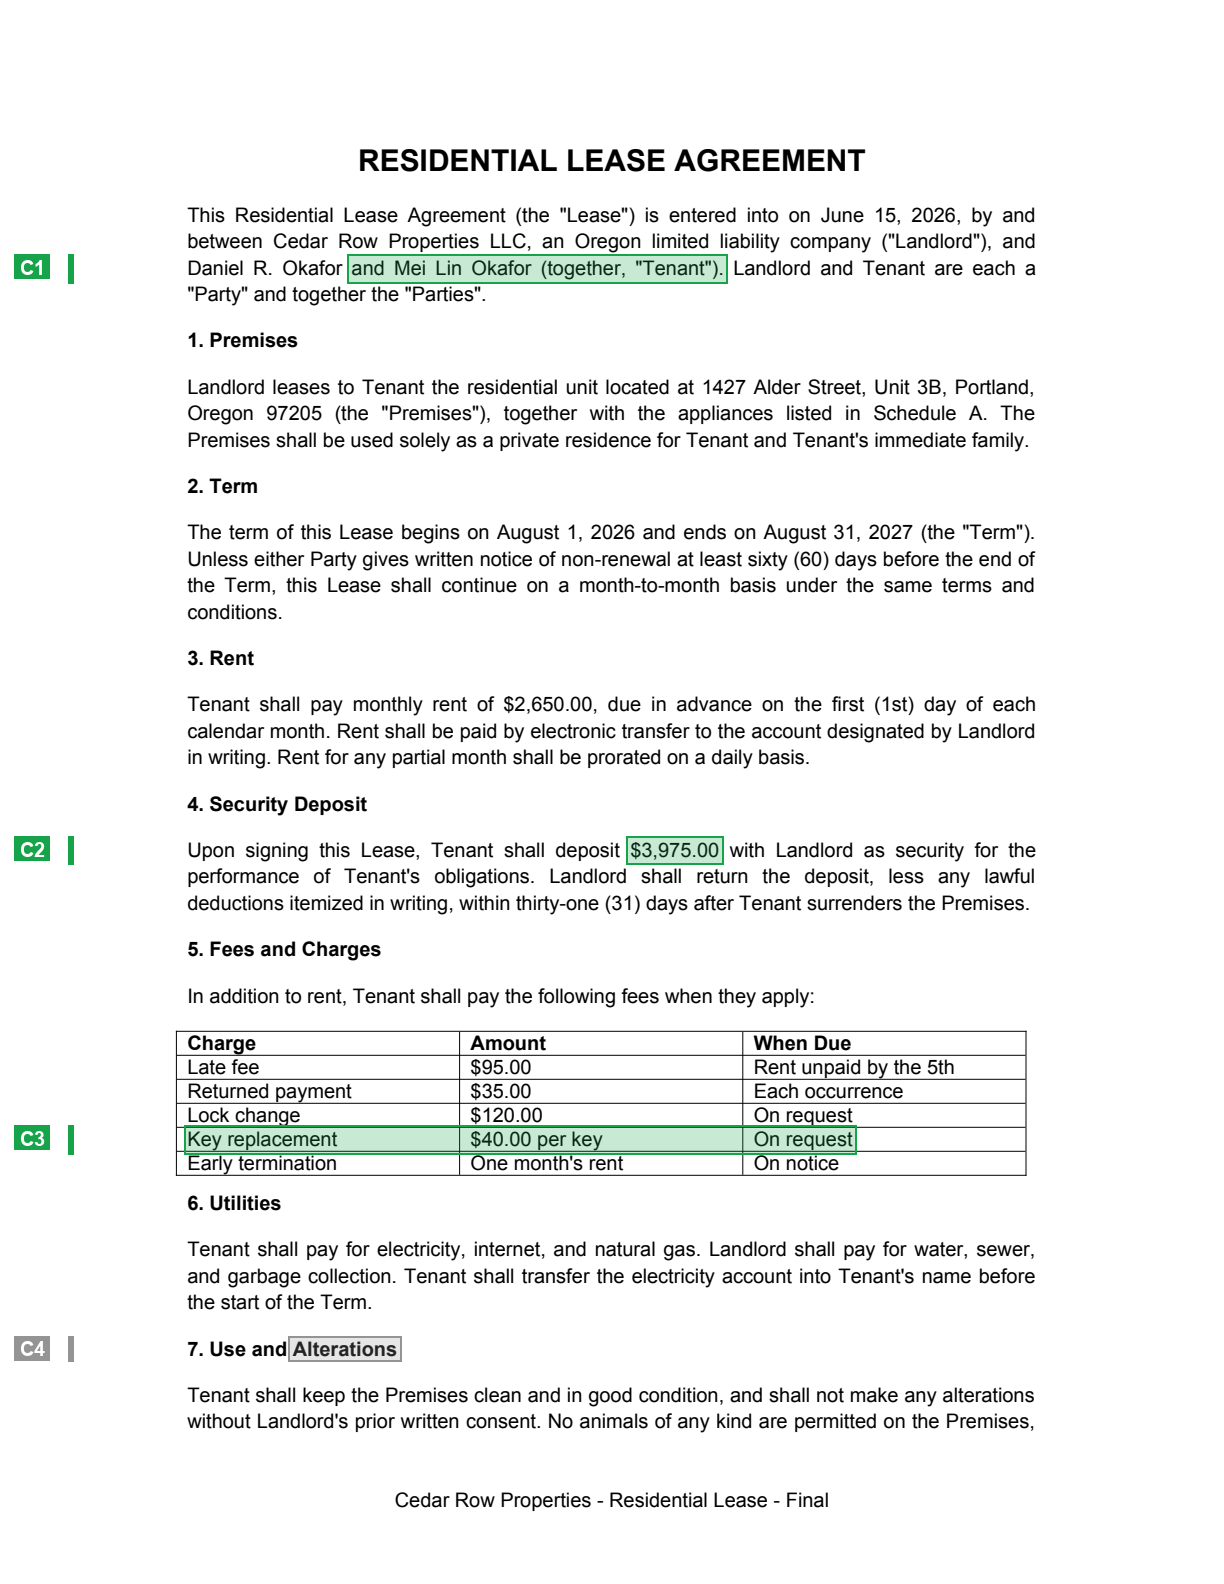

In [15]:
changes = docdiff.diff("lease_v2", "lease_v3")
show(changes)
path = docdiff.report("lease_v2", "lease_v3", changes, docdiff.ROOT / "outputs" / "lease_v2__lease_v3")
print(path)
display(Image(filename=str(path.parent / "lease_v3_p1.png"), width=700))

### Bonus (slide 15, for fast finishers)

Diff **v1 straight to v3**. Is it the sum of v1→v2 and v2→v3? Is anything set aside as noise?

In [16]:
# Solution
changes = docdiff.diff("lease_v1", "lease_v3")
show(changes)
print(len(changes), "changes,", sum(c.status == "noise" for c in changes), "set aside")
# 11 changes and nothing set aside: the Alteratioos misread only exists in v2, so it never appears here.

   C1  modified (preamble)              '("Tenant").'                     -> 'and Mei Lin Okafor (together, "Tenant"'  conf 0.79
   C2  removed  1. Premises             'Landlord shall provide one (1)'  -> ''  conf 1.00
   C3  modified 2. Term                 'July'                            -> 'August'  conf 1.00
   C4  modified 2. Term                 'thirty (30)'                     -> 'sixty (60)'  conf 1.00
   C5  modified 3. Rent                 '$2,450.00,'                      -> '$2,650.00,'  conf 1.00
   C6  modified 4. Security Deposit     '$2,450.00'                       -> '$3,975.00'  conf 1.00
   C7  modified 5. Fees and Charges     '$75.00'                          -> '$95.00'  conf 0.87
   C8  added    5. Fees and Charges     ''                                -> 'On request Key replacement $40.00 per '  conf 1.00
   C9  added    7. Use and Alterations  ''                                -> 'except that'  conf 1.00
   C10 modified 7. Use and Alterations  'not'        

## Slides 16–17 · Take it further

- **Your own documents:** put PDFs in `data/pdfs/`, run `python scripts/parse.py` (needs an ADE API key), then
  `python scripts/diff_versions.py <old> <new>`.
- **Tune the rule:** `CONFIDENCE_THRESHOLD` and `NEAR_MISS_SIMILARITY` sit at the top of `scripts/docdiff.py`.
- **Verity reads digitally created, Latin-script documents.** For scans and handwriting, parse with DPT-3 Pro,
  which grounds by line and has no per-word confidence.